=== Sensor Data Analysis Tool ===

What would you like to do?
  1) Generate new sensor readings
  2) Load readings from an existing CSV file
Readings saved to sensor_readings.csv

--- Statistics ---
Number of readings:        300
Mean:                      23.33
Minimum:                   11.01
Maximum:                   35.98
Standard deviation:        7.41
Readings above 25.0: 128

--- Readings above threshold (25.0) ---
Sample 1: 26.99
Sample 5: 29.41
Sample 6: 27.92
Sample 7: 33.3
Sample 15: 27.25
Sample 18: 25.73
Sample 19: 31.24
Sample 21: 31.15
Sample 22: 28.45
Sample 25: 34.93
Sample 29: 32.19
Sample 30: 26.09
Sample 31: 31.18
Sample 32: 29.24
Sample 34: 35.33
Sample 37: 31.74
Sample 38: 26.46
Sample 39: 32.54
Sample 40: 25.43
Sample 41: 28.61
Sample 49: 26.89
Sample 54: 34.42
Sample 55: 27.2
Sample 56: 26.23
Sample 58: 29.23
Sample 61: 35.74
Sample 62: 27.0
Sample 64: 28.12
Sample 65: 32.07
Sample 66: 30.4
Sample 72: 34.57
Sample 73: 32.91
Sample 75: 27.39
Sample 77: 33.86
Sam

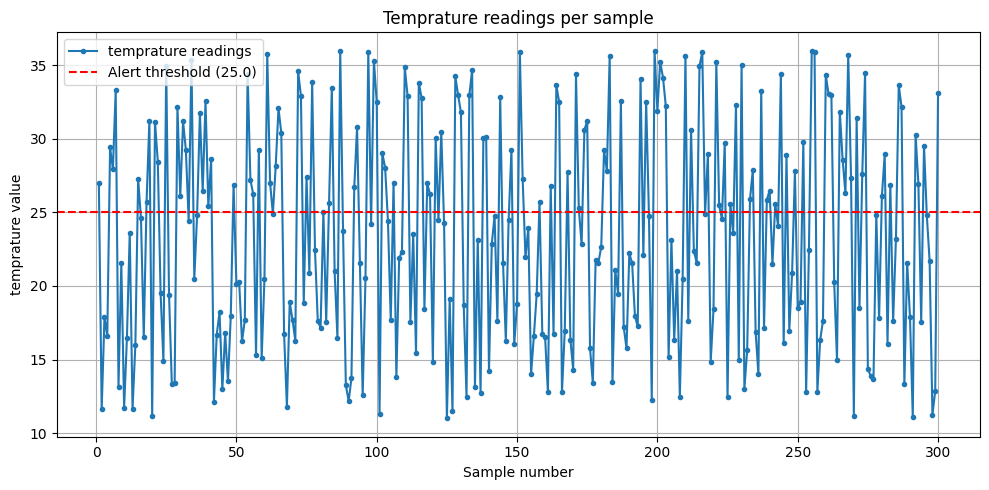

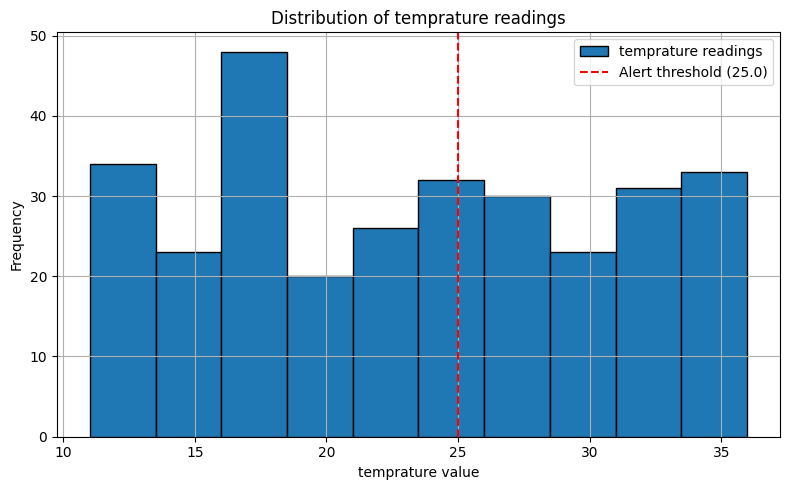

In [ ]:
"""Sensor Data Analysis Tool.

Simulates sensor readings(or loads them from a CSV file), analyzes them
with NumPy, plots them with Matplotlib and saves them with the csv module.
"""

import csv
import random

import matplotlib.pyplot as plt
import numpy as np

CSV_FILE = "sensor_readings.csv"
LINE_PLOT_FILE = "line_plot.png"
HISTOGRAM_FILE = "histogram.png"
SEED = 42


# ---------------------------------------------------------------- input helpers
def ask_float(prompt):
    """Keep asking until the user enters a valid number."""
    while True:
        text = input(prompt).strip()
        try:
            return float(text)
        except ValueError:
            print(f"  Error: '{text}' is not a number. Please try again.")


def ask_positive_int(prompt):
    """Keep asking until the user enters an integer greater than zero."""
    while True:
        text = input(prompt).strip()
        try:
            value = int(text)
        except ValueError:
            print(f"  Error: '{text}' is not a whole number. Please try again.")
            continue
        if value <= 0:
            print("  Error: the number of readings must be greater than zero.")
            continue
        return value


def get_user_input():
    """Ask for all parameters needed to generate readings."""
    sensor_type = input("Sensor type (e.g. temperature, light): ").strip() or "sensor"
    num_readings = ask_positive_int("Number of readings to generate: ")

    while True:
        min_value = ask_float("Minimum sensor value: ")
        max_value = ask_float("Maximum sensor value: ")
        if min_value >= max_value:
            print("  Error: the minimum must be smaller than the maximum.")
            continue
        break

    threshold = ask_float("Alert threshold: ")
    return sensor_type, num_readings, min_value, max_value, threshold


def get_choice():
    """Let the user choose between generating or loading data."""
    print("\nWhat would you like to do?")
    print("  1) Generate new sensor readings")
    print("  2) Load readings from an existing CSV file")
    while True:
        choice = input("Enter 1 or 2: ").strip()
        if choice in ("1", "2"):
            return choice
        print("  Error: please enter 1 or 2.")


# ------------------------------------------------------------------ data
def generate_readings(num_readings, min_value, max_value, seed=SEED):
    """Return a list of reproducible random readings between min and max."""
    random.seed(seed)
    return [round(random.uniform(min_value, max_value), 2) for _ in range(num_readings)]


def save_readings(readings, filename=CSV_FILE):
    """Save readings to a CSV file. Returns True on success."""
    try:
        with open(filename, "w", newline="") as file:
            writer = csv.writer(file)
            writer.writerow(["sample_number", "reading"])
            for number, value in enumerate(readings, start=1):
                writer.writerow([number, value])
    except OSError as error:
        print(f"Error: could not save '{filename}': {error}")
        return False
    print(f"Readings saved to {filename}")
    return True


def load_readings(filename):
    """Load readings from a CSV file. Returns a list, or None on failure."""
    readings = []
    try:
        with open(filename, newline="") as file:
            reader = csv.DictReader(file)
            if reader.fieldnames is None or "reading" not in reader.fieldnames:
                print("Error: the CSV file needs a 'reading' column.")
                return None
            for row_number, row in enumerate(reader, start=2):
                try:
                    readings.append(float(row["reading"]))
                except (TypeError, ValueError):
                    print(f"Error: invalid value on line {row_number}: {row['reading']!r}")
                    return None
    except FileNotFoundError:
        print(f"Error: file '{filename}' was not found.")
        return None
    except OSError as error:
        print(f"Error: could not read '{filename}': {error}")
        return None

    if not readings:
        print("Error: the CSV file contains no readings.")
        return None
    return readings


# -------------------------------------------------------------- analysis
def calculate_statistics(readings, threshold):
    """Return a dictionary of statistics computed with NumPy."""
    data = np.array(readings)
    return {
        "count": len(data),
        "mean": np.mean(data),
        "min": np.min(data),
        "max": np.max(data),
        "std": np.std(data),
        "above_threshold": int(np.sum(data > threshold)),
    }


def find_outliers(readings, threshold):
    """Return (sample_number, value) pairs for readings above the threshold."""
    data = np.array(readings)
    indices = np.where(data > threshold)[0]
    return [(int(i) + 1, float(data[i])) for i in indices]


def print_statistics(stats, threshold):
    """Display the statistics."""
    print("\n--- Statistics ---")
    print(f"Number of readings:        {stats['count']}")
    print(f"Mean:                      {stats['mean']:.2f}")
    print(f"Minimum:                   {stats['min']:.2f}")
    print(f"Maximum:                   {stats['max']:.2f}")
    print(f"Standard deviation:        {stats['std']:.2f}")
    print(f"Readings above {threshold}: {stats['above_threshold']}")


def print_outliers(outliers, threshold):
    """Display the readings that exceed the threshold."""
    print(f"\n--- Readings above threshold ({threshold}) ---")
    if not outliers:
        print("None.")
        return
    for sample, value in outliers:
        print(f"Sample {sample}: {value}")


# --------------------------------------------------------------- plots
def plot_readings(readings, threshold, sensor_type, filename=LINE_PLOT_FILE):
    """Line plot of readings with a horizontal threshold line."""
    samples = np.arange(1, len(readings) + 1)
    plt.figure(figsize=(10, 5))
    plt.plot(samples, readings, marker="o", markersize=3, label=f"{sensor_type} readings")
    plt.axhline(threshold, color="red", linestyle="--", label=f"Alert threshold ({threshold})")
    plt.title(f"{sensor_type.capitalize()} readings per sample")
    plt.xlabel("Sample number")
    plt.ylabel(f"{sensor_type} value")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename)
    print(f"Line plot saved to {filename}")


def plot_histogram(readings, threshold, sensor_type, filename=HISTOGRAM_FILE):
    """Histogram showing the distribution of readings."""
    plt.figure(figsize=(8, 5))
    plt.hist(readings, bins=10, edgecolor="black", label=f"{sensor_type} readings")
    plt.axvline(threshold, color="red", linestyle="--", label=f"Alert threshold ({threshold})")
    plt.title(f"Distribution of {sensor_type} readings")
    plt.xlabel(f"{sensor_type} value")
    plt.ylabel("Frequency")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename)
    print(f"Histogram saved to {filename}")


# ---------------------------------------------------------------- main
def main():
    print("=== Sensor Data Analysis Tool ===")
    choice = get_choice()

    if choice == "1":
        sensor_type, num, min_value, max_value, threshold = get_user_input()
        readings = generate_readings(num, min_value, max_value)
        save_readings(readings)
    else:
        readings = None
        while readings is None:
            filename = input("CSV file to load: ").strip()
            readings = load_readings(filename)
        sensor_type = input("Sensor type (e.g. temperature, light): ").strip() or "sensor"
        threshold = ask_float("Alert threshold: ")

    stats = calculate_statistics(readings, threshold)
    print_statistics(stats, threshold)
    print_outliers(find_outliers(readings, threshold), threshold)

    plot_readings(readings, threshold, sensor_type)
    plot_histogram(readings, threshold, sensor_type)
    plt.show()


if __name__ == "__main__":
    main()